# 09A — NFL movement-demand atlas

**Milestone 09 · Combine Intelligence Lab.** *Same stopwatch. Different movement. Better questions.*

**Question.** Which speed-change demands actually occur in NFL games, how often and how intensely, for each position the warehouse supports?

This notebook does **not** predict anything. It describes observed game movement in physical terms, so that later notebooks can ask where a prospect's measured Combine values sit inside those demands.

| Unit | Meaning |
|---|---|
| frame | one 100 ms sample — never a sample size |
| episode | one maximal run of frames meeting the rule of a demand, inside one tracking segment of one eligible player-play |
| athlete | the independent unit of every count called a sample size |

**Demand categories** (candidate physical categories, not football roles): acceleration from low speed · from intermediate speed · transition into high-speed running · sustained high-speed running · speed maintenance · braking · acceleration after braking · directional redirection (valid headings only) · repeated speed-change sequences. Rules and thresholds: `movement_demands.DemandConfig` (proposed values, fixed before any distribution was read).

**Reused, not rebuilt.** Milestone 05A eligible player-plays and context labels (`nfl_play_movement`), the Milestone 05 game-batch reader, segmentation and Savitzky–Golay kinematics. One pass over `silver.game_tracking`, cached: a second run restores the tables.

**Not inferred.** Routes, assignments, coverage techniques and rush responsibilities are never derived from a movement shape. A vendor label is carried only when the warehouse holds one.

**Prerequisite (same `RUN_MODE`).** 05A.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full' — smoke reads the first games of each season and writes under _sample
SEED = 20261011
FORCE_REBUILD = False         # True = scan the tracking again even when the cached atlas is current
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
EXPERIMENT_VERSION = '09A.1'
BUILD_EXAMPLES = True         # recorded frames of rule-chosen example episodes (one play at a time from silver; needed for the episode replay)
EXAMPLE_POSITION = 'WR'       # position drawn in the example figure of this notebook (every supported position is saved)
SHOW_TABLES = True

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import intelligence_validation as iv
from nflbdb.research.advanced_movement import movement_demands as md
from nflbdb.research.advanced_movement import nfl_outcomes as no
from nflbdb.research.advanced_movement.artifacts import IntelligenceStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = IntelligenceStore(cfg, controls)
amc.seed_everything(controls.seed)
OC = no.OutcomeConfig().for_mode(controls)
DC = md.DemandConfig().for_mode(controls)
NB = {'05A': '05a_nfl_movement_outcome_eda.ipynb', '09A': '09a_nfl_movement_demand_atlas.ipynb'}

plays = store.nfl.require(no.plays_contract(OC), NB['05A'])           # Milestone 05A: eligibility and observed context (READ ONLY)
no.assert_no_combine_columns(plays, 'play table')
builder = md.DemandBuilder(cfg, DC, OC, limit_games=OC.smoke_games if controls.smoke else None)
PROV = {'notebook': NB['09A'], 'experiment_version': EXPERIMENT_VERSION, 'run_mode': controls.run_mode, 'seed': controls.seed, 'demand_config': DC.params()}
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
n_el = int(plays['eligible'].sum())
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {n_el:,} eligible player-plays of Milestone 05A · positions in scope: {", ".join(OC.positions)}'))
display(store.describe())

**Run mode: `full`** (FULL) · 242,043 eligible player-plays of Milestone 05A · positions in scope: DB, DL, OL, TE, WR

what,where
str,str
"""run mode""","""full"""
"""tables (CSV)""","""reports/tables/advanced_moveme…"
"""datasets (Parquet + schema sid…","""warehouse/gold/advanced_moveme…"
"""figures (PNG 300 DPI, SVG, PDF…","""reports/figures/advanced_movem…"
"""models and fitted preprocessin…","""artifacts/models/advanced_move…"


## 1 · Synthetic checks

First-crossing times and band accelerations on a ramp, the demand rules on a trace with a known sequence of phases, variance components with a planted athlete share, and the support rule of thin cells. No project data is read.

In [3]:
validation = iv.run_all(iv.CHECKS_DEMANDS)
with pl.Config(fmt_str_lengths=220, tbl_rows=-1):
    display(validation)
iv.assert_all_passed(validation)

check,status,detail
str,str,str
"""first_crossing_and_band_acceleration""","""PASS""","""first-crossing times and band accelerations are exact on a ramp; unrecorded crossings give no value"""
"""demand_segmentation_on_a_known_trace""","""PASS""","""the declared demand rules recover every phase of a known trace; turns need a valid heading; edge frames are flagged"""
"""variance_components_and_profiles""","""PASS""","""variance components recover a planted athlete share; thin position × demand cells are unsupported, absent ones counted as zero"""


## 2 · Demand registry and football-context availability

The registry states, for every category: its physical definition, its intensity dimension, the dimensions reported, and **what the forty-yard dash can and cannot say about it**.

The context cell reads the *schema* of the silver tables to find a vendor route or coverage label. If none exists the column stays empty and the situation is described in physical terms only. Check the printed source columns: a label is used as recorded and its meaning is not verified here.

In [4]:
labels, LABEL_SOURCES = builder.context_labels()
print('vendor context labels found in the warehouse:', {k: v or 'none' for k, v in LABEL_SOURCES.items()})
specs = md.demand_specs(DC)
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=150):
    display(pl.DataFrame([{'demand_id': s.demand_id, 'label': s.label, 'definition': s.definition, 'primary': s.primary + ' [' + s.unit + ']',
                           'forty_analogue': s.combine_analogue or 'none'} for s in specs]))

vendor context labels found in the warehouse: {'route_label': 'silver.player_play.route_ran', 'coverage_label': 'silver.player_play.coverage_assignment'}


demand_id,label,definition,primary,forty_analogue
str,str,str,str,str
"""accel_low""","""acceleration from low speed""","""a run of frames with tangential acceleration ≥ 1 yd/s² lasting ≥ 0.5 s with a speed gain ≥ 1.5 yd/s, starting below 2 yd/s""","""mean_accel [yd/s²]""","""acc_2_4, acc_4_6"""
"""accel_mid""","""acceleration from intermediate speed""","""a run of frames with tangential acceleration ≥ 1 yd/s² lasting ≥ 0.5 s with a speed gain ≥ 1.5 yd/s, starting at 2–5 yd/s""","""mean_accel [yd/s²]""","""acc_4_6, acc_6_8"""
"""transition_high""","""transition into high-speed running""","""a run of frames with tangential acceleration ≥ 1 yd/s² lasting ≥ 0.5 s with a speed gain ≥ 1.5 yd/s, starting at ≥ 5 yd/s and reaching 7.5 yd/s""","""mean_accel [yd/s²]""","""acc_6_8"""
"""sustained_high""","""sustained high-speed running""","""speed ≥ 7.5 yd/s for ≥ 1 s""","""v_max [yd/s]""","""top_speed"""
"""speed_maintenance""","""speed maintenance""","""|tangential acceleration| < 1 yd/s² at ≥ 5 yd/s for ≥ 1 s""","""v_mean [yd/s]""","""none"""
"""braking""","""braking and deceleration""","""a run with tangential acceleration ≤ −1 yd/s² for ≥ 0.4 s from ≥ 4 yd/s with a speed drop ≥ 2 yd/s""","""mean_accel [yd/s²]""","""none"""
"""reaccel_after_brake""","""acceleration following deceleration""","""a run of frames with tangential acceleration ≥ 1 yd/s² lasting ≥ 0.5 s with a speed gain ≥ 1.5 yd/s, starting within 1 s after a braking episode""","""mean_accel [yd/s²]""","""none"""
"""redirection""","""directional redirection""","""|heading change| ≥ 45° at |yaw rate| ≥ 60 deg/s and speed ≥ 3 yd/s, every frame with a valid heading""","""heading_change_deg [deg]""","""none"""
"""repeated_change""","""repeated speed-change sequence""","""a player-play with ≥ 2 accelerating episodes and ≥ 1 braking episode""","""n_changes [episodes]""","""none"""


## 3 · Build the atlas (one pass over the tracking, cached)

Every eligible player-play of Milestone 05A is segmented into episodes. Episodes that touch a Savitzky–Golay boundary frame are kept in the episode table with `edge = True` and excluded from every profile.

**Run time.** One scan of the regular-season tracking, comparable to the 05A build. Progress is logged per game batch. A second run restores the cached tables unless `FORCE_REBUILD = True` or a parameter changed.

In [5]:
def build_atlas():
    raw = builder.compute(plays)
    return md.build_tables(raw, plays, DC, labels, LABEL_SOURCES)

T = store.build('DEMAND_ATLAS', list(md.CONTRACTS), build_atlas, params={**builder.params(), 'labels': LABEL_SOURCES}, files=builder.input_files())
episodes, registry, freq, profile, context, availability, athletes, distributions = (T[c.name] for c in md.CONTRACTS)
print(f'{episodes.height:,} episodes · {episodes["nfl_id"].n_unique()} athletes · {int(episodes["edge"].sum()):,} flagged as touching a filter edge')
with pl.Config(tbl_rows=-1, tbl_width_chars=240, fmt_str_lengths=110):
    display(registry.select('demand_id', 'label', 'measurable', 'n_episodes', 'combine_analogue', 'limitation'))
    display(availability)

13:04:00 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:DEMAND_ATLAS] computing (never run)
13:04:00 | INFO    | nflbdb.research.advanced_movement.movement_demands | [movement_demands] season 2023 batch 2/14 (games 2023081956–2023090700): 210 episodes (0s)
13:04:02 | INFO    | nflbdb.research.advanced_movement.movement_demands | [movement_demands] season 2023 batch 3/14 (games 2023091000–2023091708): 5,718 episodes (2s)
13:04:03 | INFO    | nflbdb.research.advanced_movement.movement_demands | [movement_demands] season 2023 batch 4/14 (games 2023091709–2023100101): 5,031 episodes (3s)
13:04:05 | INFO    | nflbdb.research.advanced_movement.movement_demands | [movement_demands] season 2023 batch 5/14 (games 2023100102–2023100811): 6,322 episodes (5s)
13:04:06 | INFO    | nflbdb.research.advanced_movement.movement_demands | [movement_demands] season 2023 batch 6/14 (games 2023100900–2023102207): 6,600 episodes (6s)
13:04:08 | INFO    | nflbdb.research.advanced

486,626 episodes · 399 athletes · 70,119 flagged as touching a filter edge


demand_id,label,measurable,n_episodes,combine_analogue,limitation
str,str,bool,i64,str,str
"""accel_low""","""acceleration from low speed""",true,228227,"""acc_2_4, acc_4_6""","""game movement is rarely maximal: it follows role, opportunity and play context; the 2 → 4 yd/s band spans few …"
"""accel_mid""","""acceleration from intermediate speed""",true,22875,"""acc_4_6, acc_6_8""","""game movement is rarely maximal: it follows role, opportunity and play context; a standing-start band transit …"
"""transition_high""","""transition into high-speed running""",true,1197,"""acc_6_8""","""game movement is rarely maximal: it follows role, opportunity and play context; positions that rarely reach th…"
"""sustained_high""","""sustained high-speed running""",true,15659,"""top_speed""","""game movement is rarely maximal: it follows role, opportunity and play context; an observed game speed is not …"
"""speed_maintenance""","""speed maintenance""",true,28602,"""none""","""no maintenance phase is recorded in the forty"""
"""braking""","""braking and deceleration""",true,67836,"""none""","""contact and the end of a play also produce decelerations that are not braking"""
"""reaccel_after_brake""","""acceleration following deceleration""",true,18001,"""none""","""no validated manoeuvre label; the braking rule is a provisional threshold"""
"""redirection""","""directional redirection""",true,14311,"""none""","""magnitude only (handedness of the frame unverified); heading is the direction of MOTION, not body orientation"""
"""repeated_change""","""repeated speed-change sequence""",true,19799,"""none""","""a count of episodes of this atlas, sensitive to its thresholds"""


context_var,source,n_episodes_labelled,share_labelled,n_levels,status
str,str,i64,f64,i64,str
"""side""","""nfl_play_movement (Phase 03 windows)""",486626,1.0,3,"""observed"""
"""lined_up_position""","""nfl_play_movement (Phase 03 windows)""",481473,0.989411,16,"""observed"""
"""play_class""","""nfl_play_movement (grouping of the vendor pass_result; empty code INFERRED as no_pass)""",486626,1.0,3,"""observed"""
"""down""","""nfl_play_movement""",481473,0.989411,5,"""observed"""
"""season""","""silver.games""",486626,1.0,3,"""observed"""
"""route_label""","""silver.player_play.route_ran""",132075,0.27141,12,"""observed"""
"""coverage_label""","""silver.player_play.coverage_assignment""",188501,0.387363,20,"""observed"""


## 4 · Position-specific demand profiles — frequency and exposure

Rates are **episodes per 100 eligible player-plays**, shown beside the episode and athlete counts. A cell with fewer than the declared number of episodes or athletes is marked *too few* and carries no distribution.

Only positions present in the warehouse appear. A position that is absent has no observation — it is not estimated.

position_group,demand_id,n_episodes,n_athletes,n_eligible_plays,episodes_per_100_plays,share_plays_with,median_duration_s,supported
str,str,i64,i64,i64,f64,f64,f64,bool
"""ALL""","""accel_low""",228227,398,242043,94.291923,0.81795,1.2,true
"""ALL""","""accel_mid""",22875,384,242043,9.4508,0.092591,1.1,true
"""ALL""","""braking""",67836,390,242043,28.026425,0.266027,1.3,true
"""ALL""","""reaccel_after_brake""",18001,370,242043,7.437108,0.073049,1.0,true
"""ALL""","""redirection""",14311,358,242043,5.912586,0.057494,0.7,true
"""ALL""","""repeated_change""",19799,378,242043,8.179951,0.0818,5.2,true
"""ALL""","""speed_maintenance""",28602,387,242043,11.816909,0.112137,1.4,true
"""ALL""","""sustained_high""",15659,300,242043,6.469512,0.0641,1.9,true
"""ALL""","""transition_high""",1197,181,242043,0.49454,0.004937,1.2,true


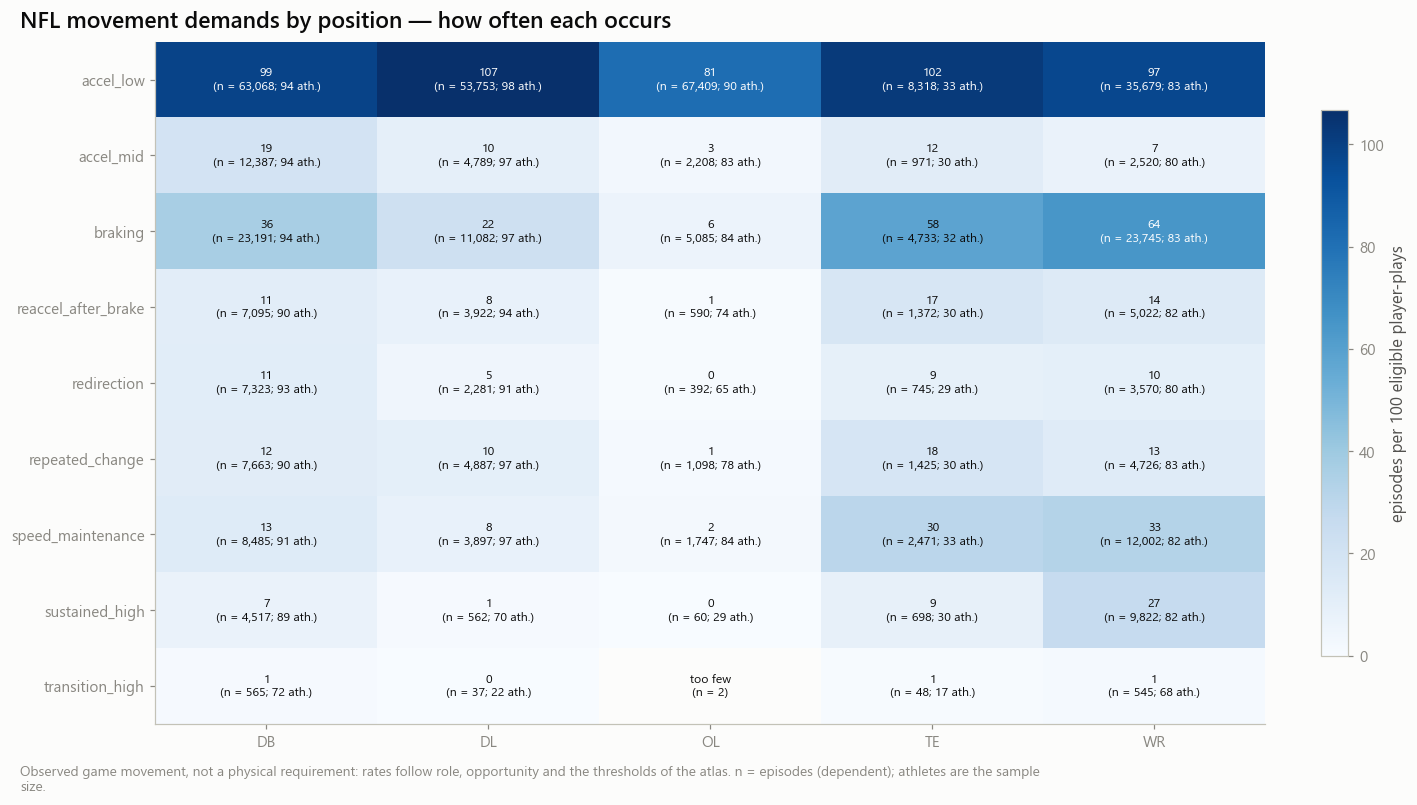

In [6]:
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=220):
        display(freq.select('position_group', 'demand_id', 'n_episodes', 'n_athletes', 'n_eligible_plays', 'episodes_per_100_plays', 'share_plays_with', 'median_duration_s', 'supported'))
store.show(ifg.fig_demand_frequency(freq), 'AM09A_01_demand_frequency_by_position', {'frequency': freq}, publication=True, source='nfl_movement_demand_frequency',
           n=f'{episodes.height:,} episodes of {episodes["nfl_id"].n_unique()} athletes')

## 5 · Movement-demand fingerprints — intensity and variability

For each demand, a small set of interpretable dimensions (speed at initiation, largest speed, speed change, duration, distance, mean acceleration, peak 0.5 s rate, band accelerations, heading change) with their quantiles by position.

**Within- versus across-athlete variability.** `athlete_share` is the between-athlete share of episode variance (one-way method of moments). A small share means an episode value mostly reflects the play, not the athlete — consistent with the Milestone 07A finding that NFL movement windows are dominated by context.

position_group,demand_id,feature,unit,n_episodes,n_athletes,q10,q50,q90,within_athlete_sd,between_athlete_sd,athlete_share,supported
str,str,str,str,i64,i64,f64,f64,f64,f64,f64,f64,bool
"""ALL""","""accel_low""","""mean_accel""","""yd/s²""",228227,398,1.882869,2.701945,3.766109,0.602423,0.39769,0.303524,true
"""ALL""","""accel_mid""","""mean_accel""","""yd/s²""",22875,384,1.673489,2.252742,3.054803,0.503997,0.192386,0.127179,true
"""ALL""","""braking""","""mean_accel""","""yd/s²""",67836,390,-4.563375,-3.060575,-2.015705,0.941019,0.25773,0.069778,true
"""ALL""","""reaccel_after_brake""","""mean_accel""","""yd/s²""",18001,370,2.021114,2.928012,4.115535,0.770517,0.234251,0.084607,true
"""ALL""","""redirection""","""heading_change_deg""","""deg""",14311,358,47.956796,63.288612,99.803417,23.162981,3.858375,0.026998,true
"""ALL""","""repeated_change""","""n_changes""","""episodes""",19799,378,3.0,3.0,4.0,0.498542,0.065865,0.017155,true
"""ALL""","""speed_maintenance""","""v_mean""","""yd/s""",28602,387,5.363012,6.682812,8.579698,1.029288,0.610332,0.26014,true
"""ALL""","""sustained_high""","""v_max""","""yd/s""",15659,300,7.935613,8.466034,9.350145,0.529546,0.145731,0.070403,true
"""ALL""","""transition_high""","""mean_accel""","""yd/s²""",1197,181,1.480069,1.80798,2.257569,0.349895,0.035818,0.010371,true


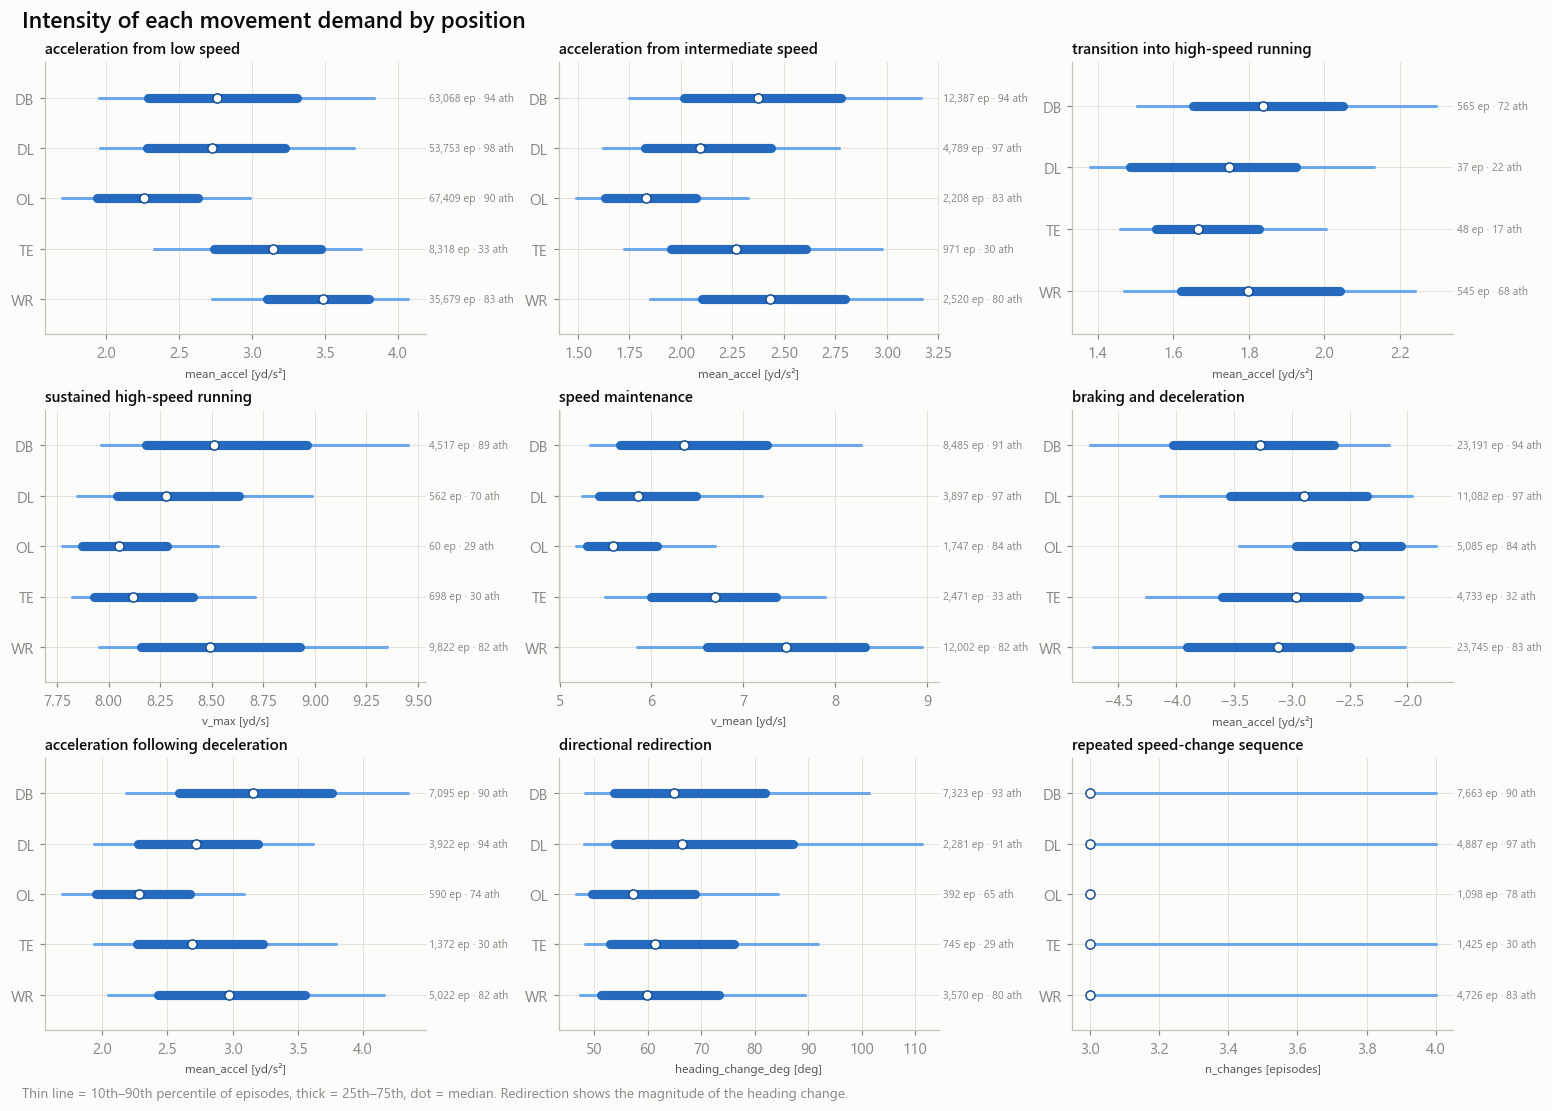

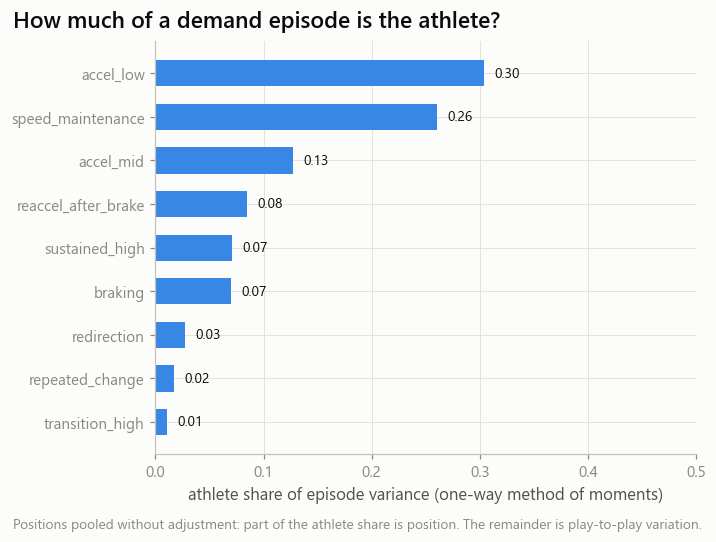

In [7]:
if SHOW_TABLES:
    with pl.Config(tbl_rows=-1, tbl_width_chars=240):
        display(profile.filter(pl.col('is_primary')).select('position_group', 'demand_id', 'feature', 'unit', 'n_episodes', 'n_athletes', 'q10', 'q50', 'q90',
                                                              'within_athlete_sd', 'between_athlete_sd', 'athlete_share', 'supported'))
store.show(ifg.fig_demand_profiles(profile, registry), 'AM09A_02_demand_intensity_by_position', {'profile': profile.filter(pl.col('is_primary'))}, publication=True,
           source='nfl_movement_demand_profiles', n='episodes and athletes annotated per row')
store.show(ifg.fig_athlete_share(profile), 'AM09A_03_athlete_share_of_episode_variance', {'profile': profile.filter(pl.col('is_primary') & (pl.col('position_group') == md.ALL))},
           source='nfl_movement_demand_profiles', n='all positions pooled')

## 6 · Football situation context

Demand counts and median intensity by the context levels that are actually observed: side of the ball, alignment, play class, down, season — and a vendor route or coverage label when one exists. No level is inferred from movement.

In [8]:
with pl.Config(tbl_rows=60, tbl_width_chars=220):
    for var in ('side', 'play_class'):
        t = context.filter(pl.col('context_var') == var).pivot(on='level', index=['position_group', 'demand_id'], values='n_episodes').sort('position_group', 'demand_id')
        print(f'episodes by {var}')
        display(t)

episodes by side


position_group,demand_id,defense,offense,unknown
str,str,i64,i64,i64
"""DB""","""accel_low""",63041,27,null
"""DB""","""accel_mid""",12386,1,null
"""DB""","""braking""",23172,19,null
"""DB""","""reaccel_after_brake""",7087,8,null
"""DB""","""redirection""",7320,3,null
"""DB""","""repeated_change""",7655,8,null
"""DB""","""speed_maintenance""",8482,3,null
"""DB""","""sustained_high""",4517,null,null
"""DB""","""transition_high""",565,null,null


episodes by play_class


position_group,demand_id,no_pass,pass,sack_or_scramble
str,str,i64,i64,i64
"""DB""","""accel_low""",22856,35253,4959
"""DB""","""accel_mid""",2917,8411,1059
"""DB""","""braking""",6775,14090,2326
"""DB""","""reaccel_after_brake""",1210,4968,917
"""DB""","""redirection""",1379,5223,721
"""DB""","""repeated_change""",1567,5192,904
"""DB""","""speed_maintenance""",1710,5999,776
"""DB""","""sustained_high""",692,3394,431
"""DB""","""transition_high""",87,431,47


## 7 · Example episodes — real plays chosen by rule

For each supported position × demand cell, the episode whose intensity is closest to the declared quantiles of that cell (ties broken by identifiers). The recorded frames are read from silver one play at a time and saved with a short margin before and after. Positions are stored as **displacements from the start of the episode** — no field landmark is reconstructed.

An example that cannot be read is reported and is not replaced by another play.

13:06:17 | INFO    | nflbdb.research.advanced_movement.artifacts | [advanced_movement:DEMAND_EXAMPLES] computing (never run)
13:06:22 | INFO    | nflbdb.research.sprint_rescue.store | [advanced_movement:DEMAND_EXAMPLES] nfl_movement_demand_examples: 3,940 rows → warehouse/gold/advanced_movement/intelligence_v1/nfl_movement_demand_examples.parquet


132 example episodes chosen; 0 could not be read: none
132 example episodes, 3,940 frames


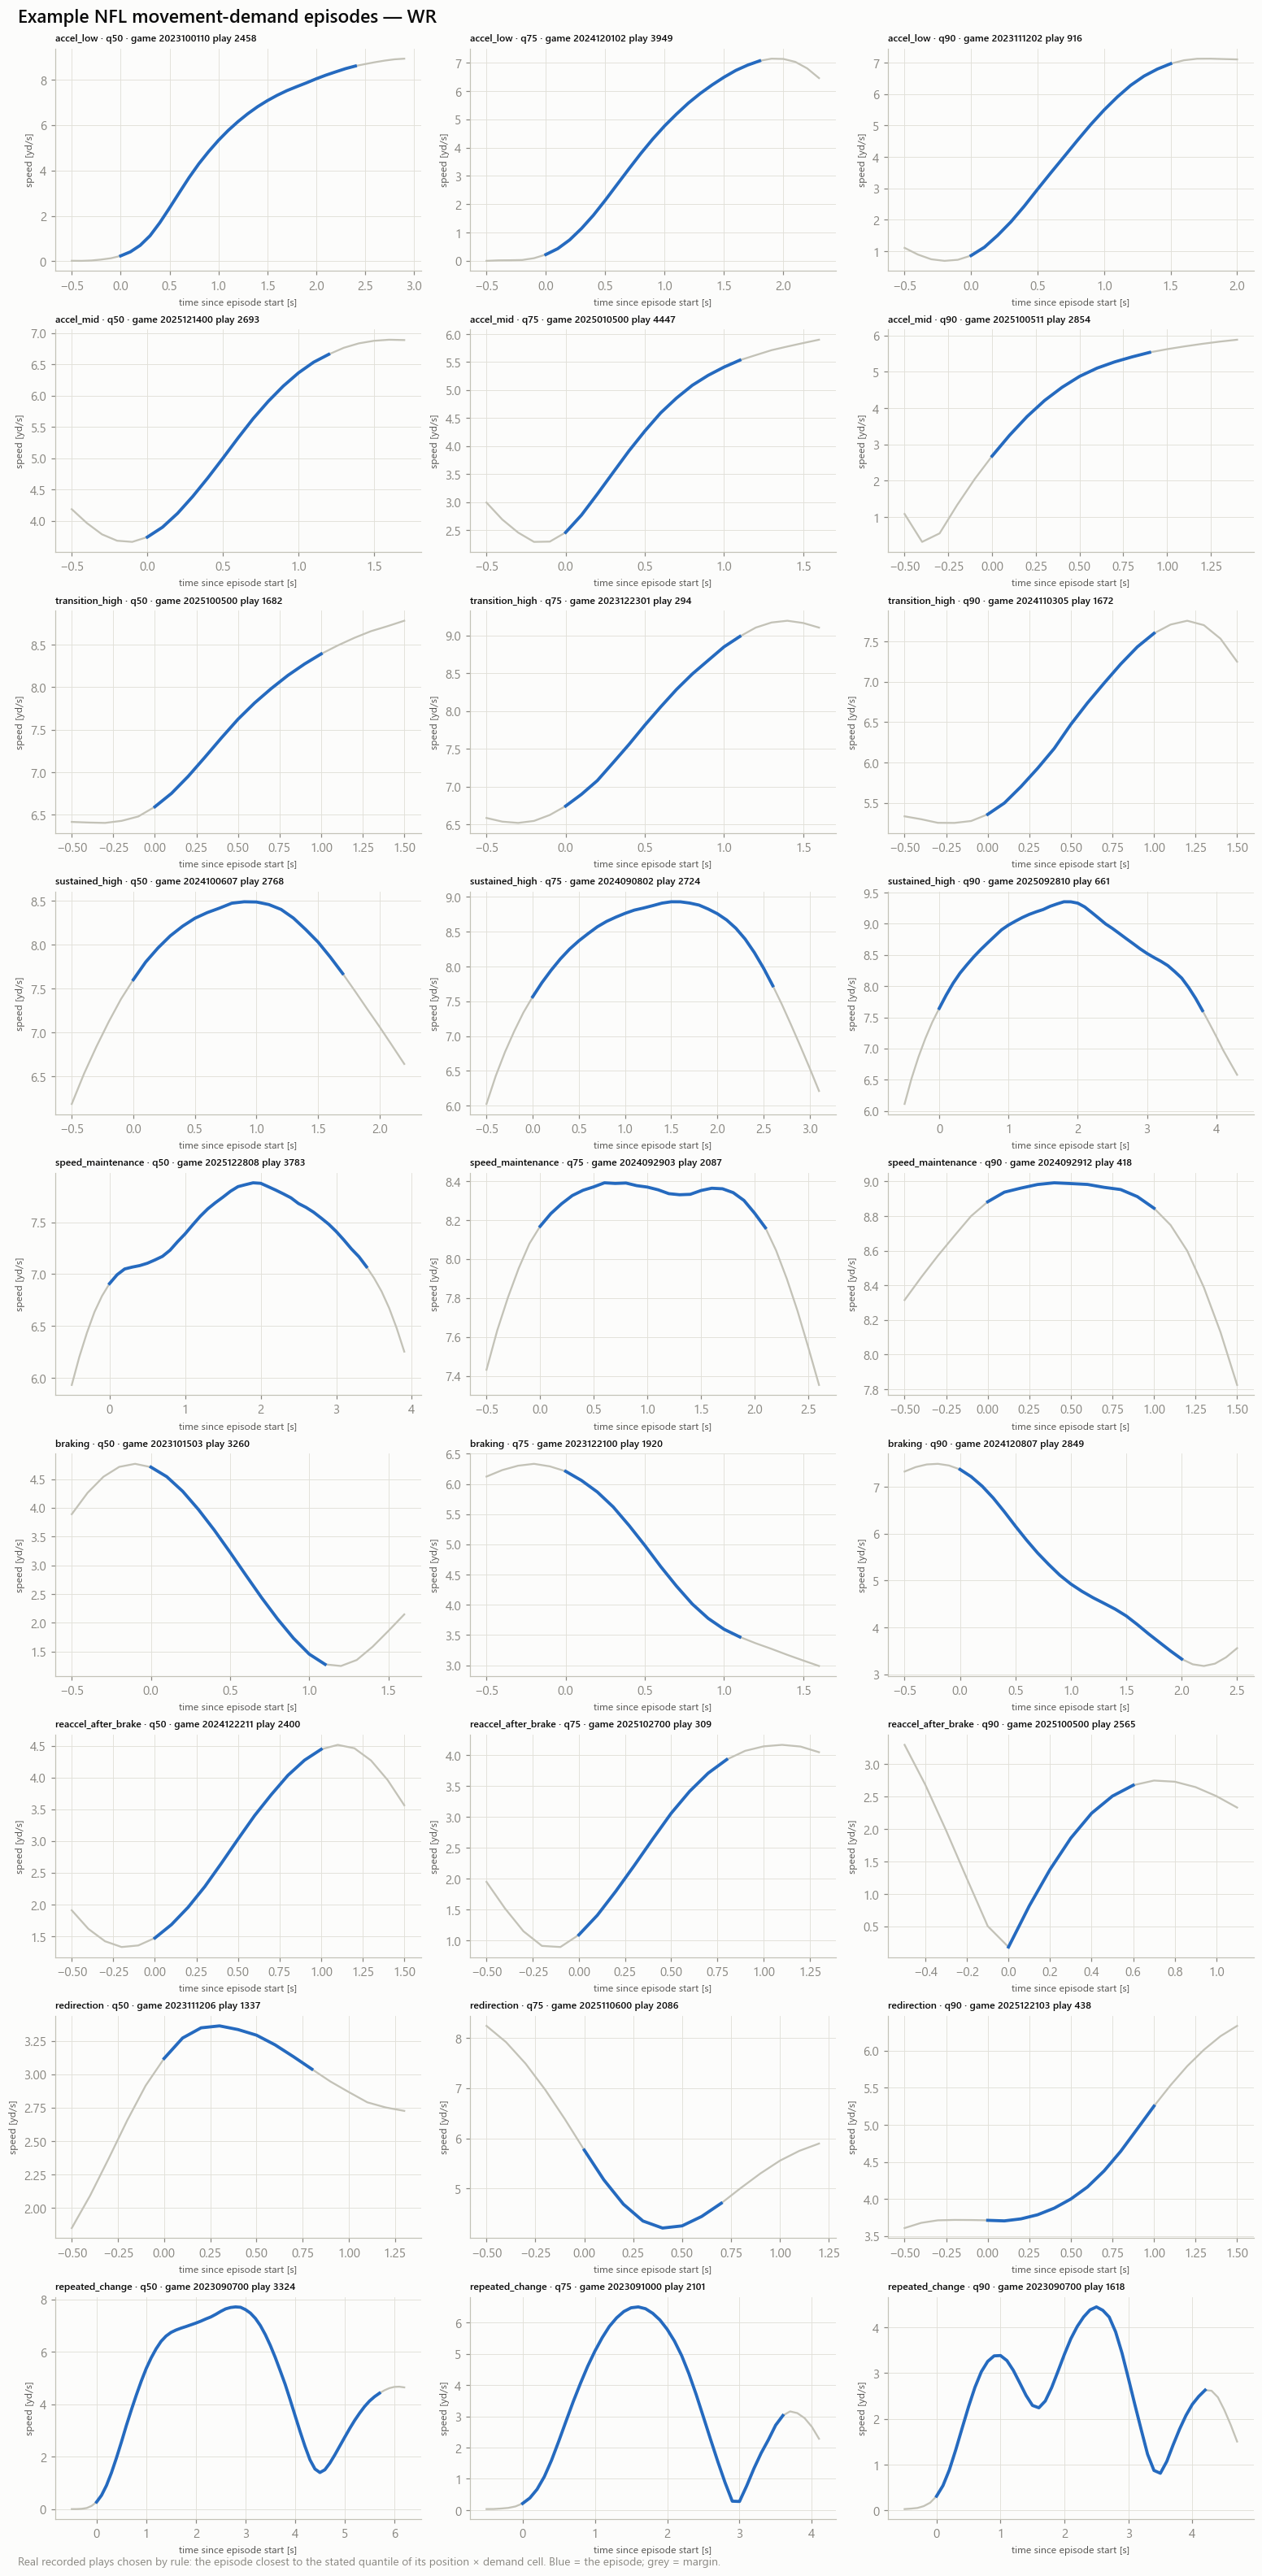

In [9]:
examples = None
if BUILD_EXAMPLES:
    def build_examples():
        chosen = md.choose_examples(episodes, freq, DC)
        frames, failed = builder.example_frames(chosen)
        print(f'{chosen.height} example episodes chosen; {len(failed)} could not be read: {failed or "none"}')
        return {md.EXAMPLES.name: frames}

    examples = store.build('DEMAND_EXAMPLES', [md.EXAMPLES], build_examples, params={'demands': DC.params(), 'n_episodes': episodes.height})[md.EXAMPLES.name]
    print(f'{examples["example_id"].n_unique()} example episodes, {examples.height:,} frames')
    store.show(ifg.fig_examples(examples, EXAMPLE_POSITION), f'AM09A_04_example_episodes_{EXAMPLE_POSITION}', {}, publication=True, source='nfl_movement_demand_examples',
               n='one real play per panel')
else:
    print('BUILD_EXAMPLES is False: no example frames (the application shows no episode replay)')

## 8 · Reading and output contract

The sentences below are assembled from the tables of this run.

| Output (`warehouse/gold/advanced_movement/intelligence_v1/`) | Grain |
|---|---|
| `nfl_movement_demand_episodes` | player-play × episode |
| `nfl_movement_demand_registry` | demand |
| `nfl_movement_demand_frequency` | position × demand |
| `nfl_movement_demand_profiles` | position × demand × dimension |
| `nfl_movement_demand_context`, `…_context_availability` | context level |
| `nfl_movement_demand_athletes` | athlete × demand |
| `nfl_movement_demand_distributions` | histogram bins |
| `nfl_movement_demand_examples` | example × frame |

**What this is not.** Observed game movement follows role, opportunity and play context. A rate is not a requirement, an observed speed is not a maximum, and nothing here says that an athlete who shows more of a demand is a better player.

In [10]:
reading = md.conclusions(freq, profile, availability)
display(Markdown('\n'.join('- ' + s for s in reading)))
if controls.save_tables:
    store.write_json('movement_demand_manifest', {'experiment_version': EXPERIMENT_VERSION, 'finished_at': utc_now(), 'n_episodes': episodes.height,
                                                  'n_athletes': int(episodes['nfl_id'].n_unique()), 'positions': sorted(episodes['position_group'].unique().to_list()),
                                                  'label_sources': LABEL_SOURCES, 'examples': None if examples is None else int(examples['example_id'].n_unique()),
                                                  'reading': reading, 'provenance': PROV})
print('Send back: the checks table, the registry and availability tables, the frequency table, figures AM09A_01 and AM09A_02, and the reading above.')
print('Next: 09b_cross_domain_movement_matching.ipynb')

- Positions supported by the warehouse: DB, DL, OL, TE, WR. A position absent from this list has no observation and is not shown.
- accel_low: 228,227 episodes of 398 athletes, 94.3 per 100 eligible player-plays.
- braking: 67,836 episodes of 390 athletes, 28.0 per 100 eligible player-plays.
- speed_maintenance: 28,602 episodes of 387 athletes, 11.8 per 100 eligible player-plays.
- accel_mid: 22,875 episodes of 384 athletes, 9.5 per 100 eligible player-plays.
- repeated_change: 19,799 episodes of 378 athletes, 8.2 per 100 eligible player-plays.
- reaccel_after_brake: 18,001 episodes of 370 athletes, 7.4 per 100 eligible player-plays.
- sustained_high: 15,659 episodes of 300 athletes, 6.5 per 100 eligible player-plays.
- redirection: 14,311 episodes of 358 athletes, 5.9 per 100 eligible player-plays.
- transition_high: 1,197 episodes of 181 athletes, 0.5 per 100 eligible player-plays.
- accel_low — mean_accel: athlete share of episode variance 0.30 (the rest is play-to-play).
- accel_mid — mean_accel: athlete share of episode variance 0.13 (the rest is play-to-play).
- braking — mean_accel: athlete share of episode variance 0.07 (the rest is play-to-play).
- reaccel_after_brake — mean_accel: athlete share of episode variance 0.08 (the rest is play-to-play).
- redirection — heading_change_deg: athlete share of episode variance 0.03 (the rest is play-to-play).
- repeated_change — n_changes: athlete share of episode variance 0.02 (the rest is play-to-play).
- speed_maintenance — v_mean: athlete share of episode variance 0.26 (the rest is play-to-play).
- sustained_high — v_max: athlete share of episode variance 0.07 (the rest is play-to-play).
- transition_high — mean_accel: athlete share of episode variance 0.01 (the rest is play-to-play).
- Context labels not held by the warehouse (physical description only): none.

Send back: the checks table, the registry and availability tables, the frequency table, figures AM09A_01 and AM09A_02, and the reading above.
Next: 09b_cross_domain_movement_matching.ipynb
